### Import libraries

In [1]:
# Import libraries for data analysis and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style for charts
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

### Load the cleaned dataset

In [2]:
# Load the cleaned traffic dataset
df = pd.read_csv(r"C:\Users\KIIT\gfg_project\GFG_project\data\processed\urban_traffic_cleaned.csv")

# Convert timestamp to datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Display dataset size and first five rows
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (69120, 25)


,timestamp,intersection_id,hour,minute,day_of_week,is_weekend,is_holiday,event_nearby,temperature_c,rain_mm_15min,...,queue_length_veh,incident_flag,prev_count_15min,prev_count_1h,count_same_time_yesterday,count_same_time_last_week,rolling_mean_1h,target_next_count,target_congestion,n_imputed_sensor_values
0,2025-01-06 00:00:00,INT_01_CBD,0,0,0,0,0,0,2.6,0.0,...,1.5,0,NaN,NaN,NaN,NaN,NaN,36.0,Low,0
1,2025-01-06 00:15:00,INT_01_CBD,0,15,0,0,0,0,2.7,0.0,...,0.3,0,23.0,NaN,NaN,NaN,NaN,28.0,Low,0
2,2025-01-06 00:30:00,INT_01_CBD,0,30,0,0,0,0,2.4,0.0,...,0.0,0,36.0,NaN,NaN,NaN,NaN,33.0,Low,0
3,2025-01-06 00:45:00,INT_01_CBD,0,45,0,0,0,0,1.5,0.0,...,0.4,0,28.0,NaN,NaN,NaN,NaN,19.0,Low,0
4,2025-01-06 01:00:00,INT_01_CBD,1,0,0,0,0,0,3.1,0.0,...,0.0,0,33.0,23.0,NaN,NaN,30.0,32.0,Low,0


### Understand the dataset

In [3]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Display data types and non-missing counts
df.info()

# Display statistical summary
display(df.describe())

Column names:
['timestamp', 'intersection_id', 'hour', 'minute', 'day_of_week', 'is_weekend', 'is_holiday', 'event_nearby', 'temperature_c', 'rain_mm_15min', 'road_capacity_veh_15min', 'vehicle_count', 'avg_speed_kmh', 'vehicle_density_per_km', 'avg_waiting_time_sec', 'queue_length_veh', 'incident_flag', 'prev_count_15min', 'prev_count_1h', 'count_same_time_yesterday', 'count_same_time_last_week', 'rolling_mean_1h', 'target_next_count', 'target_congestion', 'n_imputed_sensor_values']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69120 entries, 0 to 69119
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   timestamp                  69120 non-null  datetime64[ns]
 1   intersection_id            69120 non-null  object        
 2   hour                       69120 non-null  int64         
 3   minute                     69120 non-null  int64         
 4   day_of_week        

,timestamp,hour,minute,day_of_week,is_weekend,is_holiday,event_nearby,temperature_c,rain_mm_15min,road_capacity_veh_15min,...,avg_waiting_time_sec,queue_length_veh,incident_flag,prev_count_15min,prev_count_1h,count_same_time_yesterday,count_same_time_last_week,rolling_mean_1h,target_next_count,n_imputed_sensor_values
count,69120,69120.000000,69120.000000,69120.000000,69120.000000,69120.000000,69120.000000,69120.000000,69120.000000,69120.000000,...,69120.000000,69120.000000,69120.000000,69116.000000,69104.000000,68736.000000,66432.000000,69104.000000,69116.000000,69120.000000
mean,2025-04-05 23:52:30,11.500000,22.500000,2.972222,0.277778,0.022222,0.003241,17.247575,0.311576,395.000000,...,21.110823,16.390699,0.022989,134.419165,134.437876,134.317039,134.502183,134.438082,134.419252,0.039959
min,2025-01-06 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.000000,260.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,5.250000,1.000000,0.000000
25%,2025-02-19 23:56:15,5.750000,11.250000,1.000000,0.000000,0.000000,0.000000,11.600000,0.000000,350.000000,...,8.600000,1.100000,0.000000,32.000000,32.000000,32.000000,32.000000,32.500000,32.000000,0.000000
50%,2025-04-05 23:52:30,11.500000,22.500000,3.000000,0.000000,0.000000,0.000000,18.000000,0.000000,400.000000,...,14.100000,4.100000,0.000000,85.000000,85.000000,85.000000,85.000000,86.250000,85.000000,0.000000
75%,2025-05-20 23:48:45,17.250000,33.750000,5.000000,1.000000,0.000000,0.000000,22.900000,0.000000,445.000000,...,24.200000,14.200000,0.000000,190.000000,190.000000,190.000000,190.000000,190.750000,190.000000,0.000000
max,2025-07-04 23:45:00,23.000000,45.000000,6.000000,1.000000,1.000000,1.000000,31.500000,12.300000,520.000000,...,118.900000,165.200000,1.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,2.000000
std,NaN,6.922237,16.770631,1.992864,0.447906,0.147407,0.056836,7.338541,1.027159,93.140354,...,20.982459,30.284207,0.149869,135.018348,135.022521,134.914175,135.110203,133.071987,135.018241,0.198944


### Check missing values and duplicates

In [4]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
timestamp                       0
intersection_id                 0
hour                            0
minute                          0
day_of_week                     0
is_weekend                      0
is_holiday                      0
event_nearby                    0
temperature_c                   0
rain_mm_15min                   0
road_capacity_veh_15min         0
vehicle_count                   0
avg_speed_kmh                   0
vehicle_density_per_km          0
avg_waiting_time_sec            0
queue_length_veh                0
incident_flag                   0
prev_count_15min                4
prev_count_1h                  16
count_same_time_yesterday     384
count_same_time_last_week    2688
rolling_mean_1h                16
target_next_count               4
target_congestion               4
n_imputed_sensor_values         0
dtype: int64

Duplicate rows: 0


### Congestion class balance

target_congestion
Low         42575
Moderate    15800
Severe       5744
High         4997
Name: count, dtype: int64


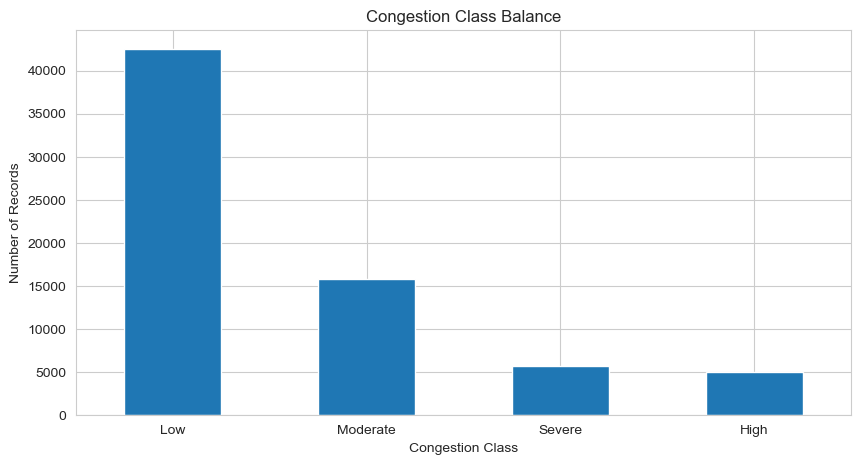

In [6]:
# Check how many records belong to each congestion class
if "target_congestion" in df.columns:
    print(df["target_congestion"].value_counts())

    # Plot the number of records in each class
    df["target_congestion"].value_counts().plot(kind="bar")

    plt.title("Congestion Class Balance")
    plt.xlabel("Congestion Class")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=0)
    plt.show()
else:
    print("Congestion target column not found.")

### Vehicle count distribution

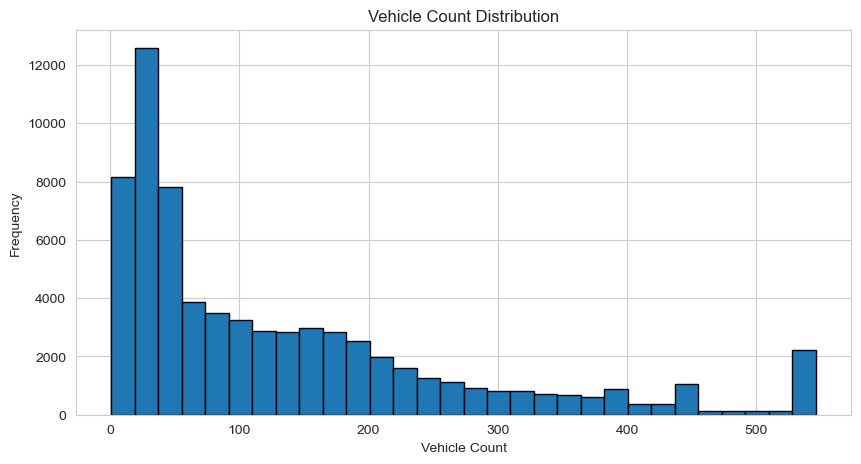

In [7]:
# Plot the distribution of vehicle counts
plt.hist(df["vehicle_count"].dropna(), bins=30, edgecolor="black")

plt.title("Vehicle Count Distribution")
plt.xlabel("Vehicle Count")
plt.ylabel("Frequency")
plt.show()

### Average speed distribution

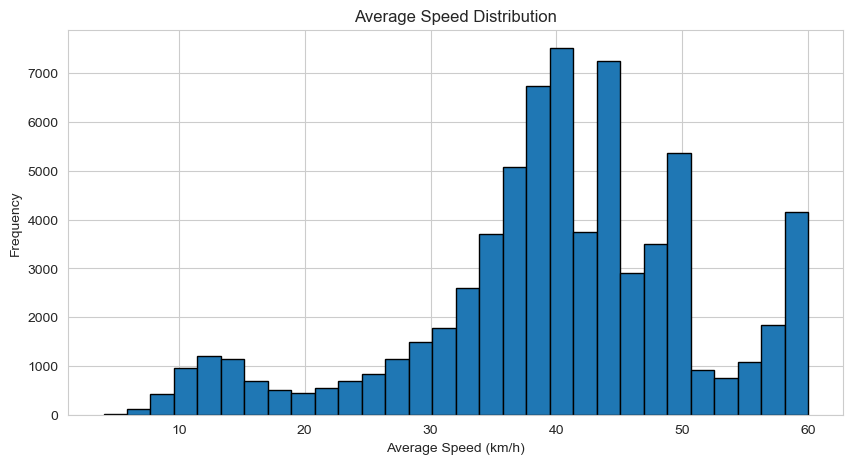

In [8]:
# Plot the distribution of average vehicle speeds
plt.hist(df["avg_speed_kmh"].dropna(), bins=30, edgecolor="black")

plt.title("Average Speed Distribution")
plt.xlabel("Average Speed (km/h)")
plt.ylabel("Frequency")
plt.show()

### Hourly traffic — weekday vs weekend

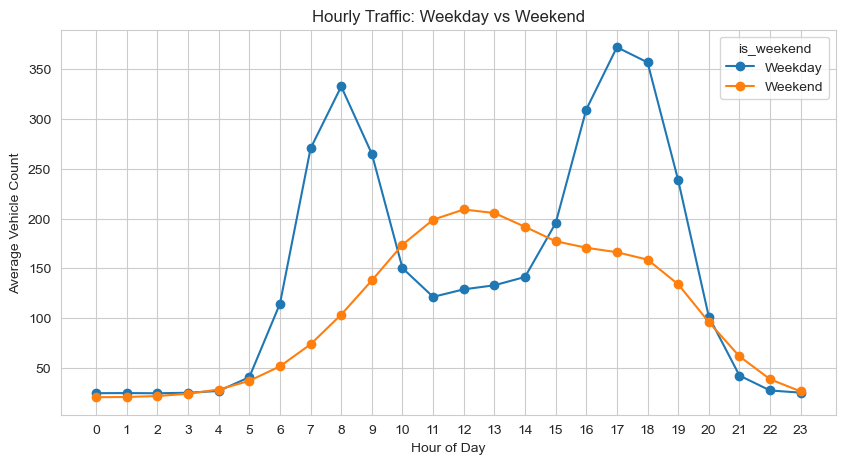

In [9]:
# Compare average vehicle count for weekdays and weekends
hourly_traffic = df.groupby(
    ["hour", "is_weekend"]
)["vehicle_count"].mean().unstack()

# Plot both traffic profiles
hourly_traffic = hourly_traffic.rename(
    columns={0: "Weekday", 1: "Weekend"}
)

hourly_traffic.plot(marker="o")

plt.title("Hourly Traffic: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Average Vehicle Count")
plt.xticks(range(0, 24))
plt.show()

### Utilisation heatmap

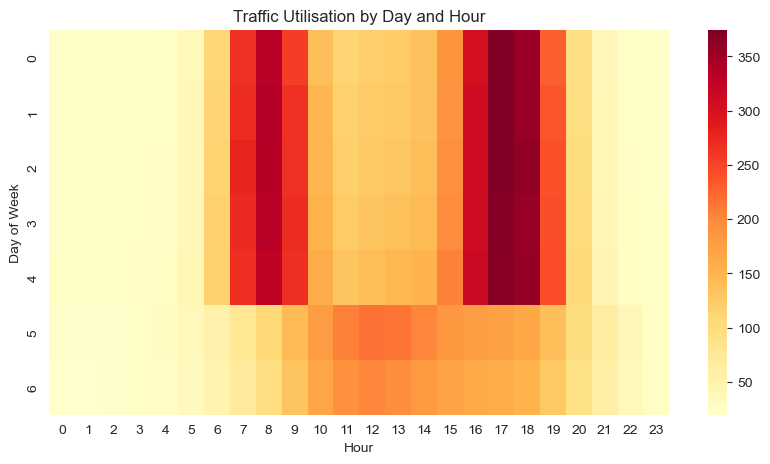

In [10]:
# Calculate average traffic for each day and hour
traffic_table = df.pivot_table(
    index="day_of_week",
    columns="hour",
    values="vehicle_count",
    aggfunc="mean"
)

# Plot the traffic intensity heatmap
sns.heatmap(traffic_table, cmap="YlOrRd")

plt.title("Traffic Utilisation by Day and Hour")
plt.xlabel("Hour")
plt.ylabel("Day of Week")
plt.show()

### One-week traffic time series

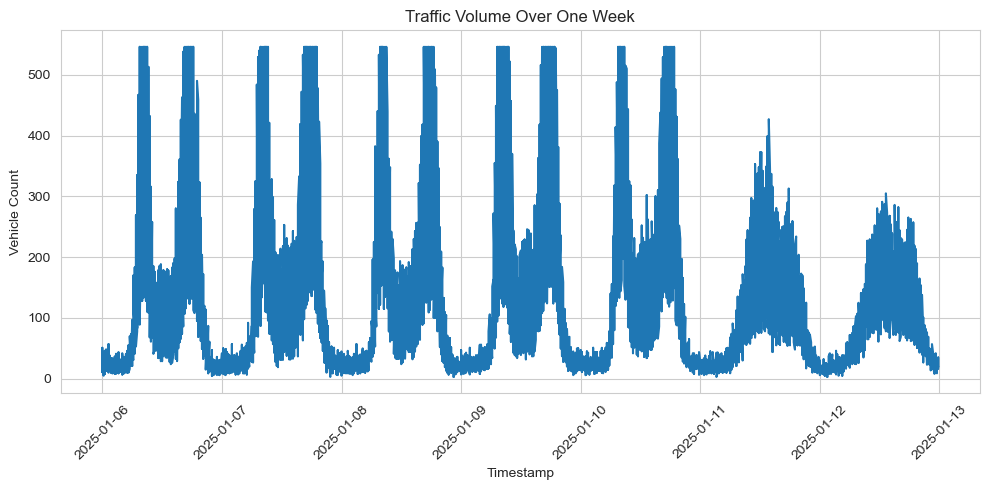

In [12]:
# Sort the data by timestamp
time_df = df.dropna(subset=["timestamp"]).sort_values("timestamp")

# Select the first seven days of available data
start_date = time_df["timestamp"].min()
one_week = time_df[
    time_df["timestamp"] < start_date + pd.Timedelta(days=7)
]

# Plot vehicle count over time
plt.plot(one_week["timestamp"], one_week["vehicle_count"])

plt.title("Traffic Volume Over One Week")
plt.xlabel("Timestamp")
plt.ylabel("Vehicle Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Speed vs traffic load

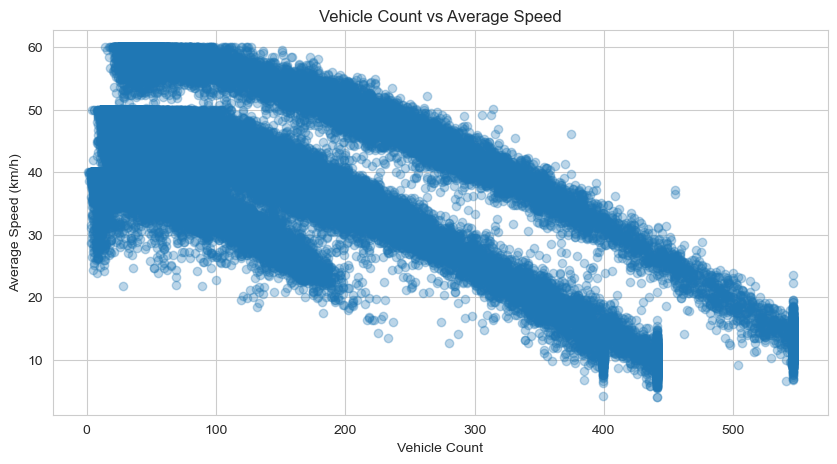

In [13]:
# Compare vehicle count with average speed
plt.scatter(
    df["vehicle_count"],
    df["avg_speed_kmh"],
    alpha=0.3
)

plt.title("Vehicle Count vs Average Speed")
plt.xlabel("Vehicle Count")
plt.ylabel("Average Speed (km/h)")
plt.show()

### Rain effect on speed

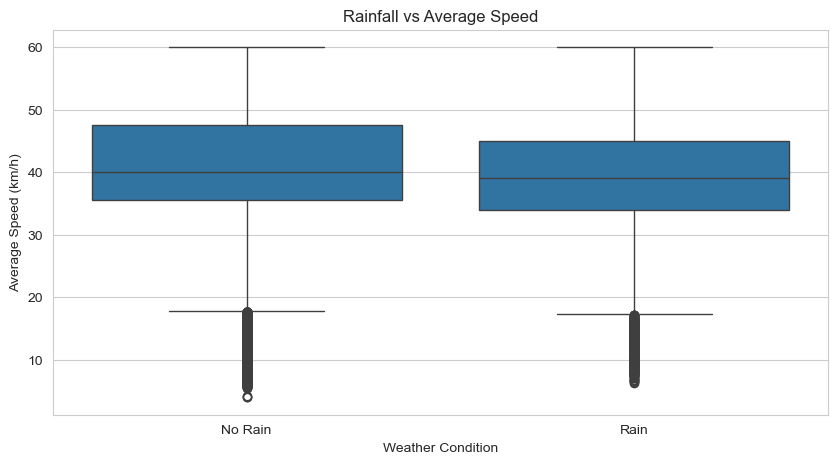

In [14]:
# Compare vehicle speed during rainy and dry conditions
df["rain_status"] = (df["rain_mm_15min"] > 0).map({
    False: "No Rain",
    True: "Rain"
})

# Plot speed distributions for both conditions
sns.boxplot(data=df, x="rain_status", y="avg_speed_kmh")

plt.title("Rainfall vs Average Speed")
plt.xlabel("Weather Condition")
plt.ylabel("Average Speed (km/h)")
plt.show()

### Incident impact

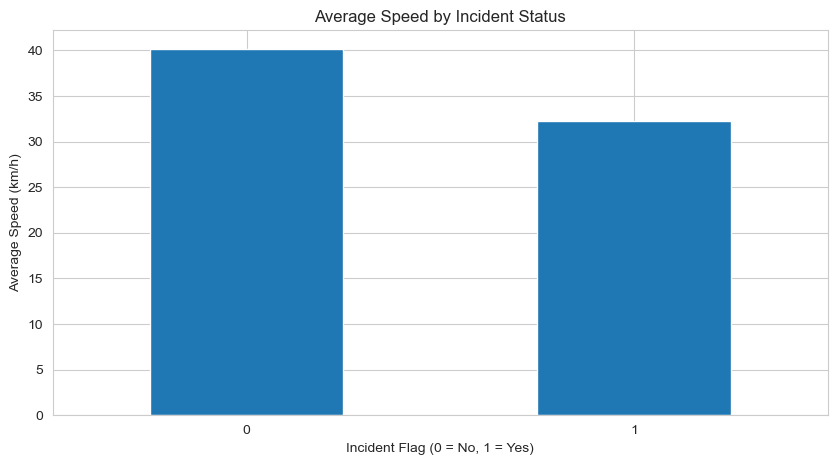

In [15]:
# Calculate average speed with and without incidents
incident_speed = df.groupby("incident_flag")["avg_speed_kmh"].mean()

# Plot the comparison
incident_speed.plot(kind="bar")

plt.title("Average Speed by Incident Status")
plt.xlabel("Incident Flag (0 = No, 1 = Yes)")
plt.ylabel("Average Speed (km/h)")
plt.xticks(rotation=0)
plt.show()

### Correlation heatmap

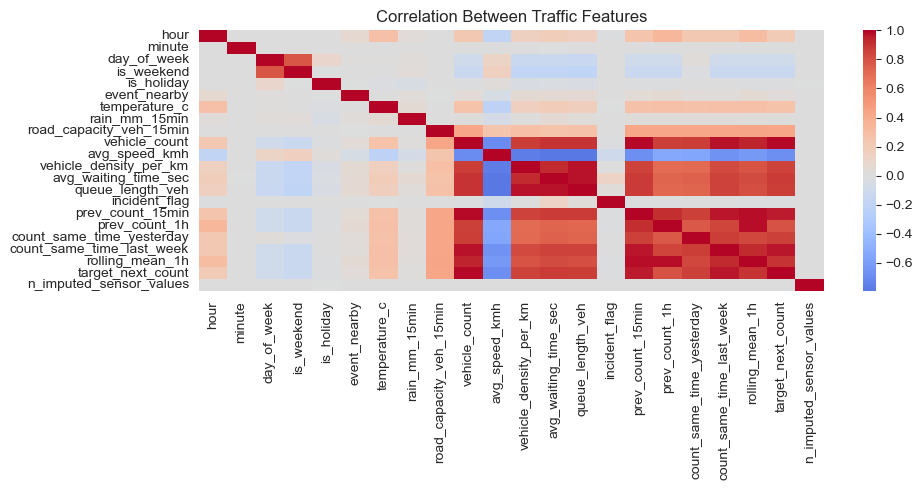

In [16]:
# Select numerical columns and calculate their correlations
correlation = df.select_dtypes(include="number").corr()

# Plot correlations between numerical features
sns.heatmap(correlation, cmap="coolwarm", center=0)

plt.title("Correlation Between Traffic Features")
plt.tight_layout()
plt.show()

### Congestion by hour

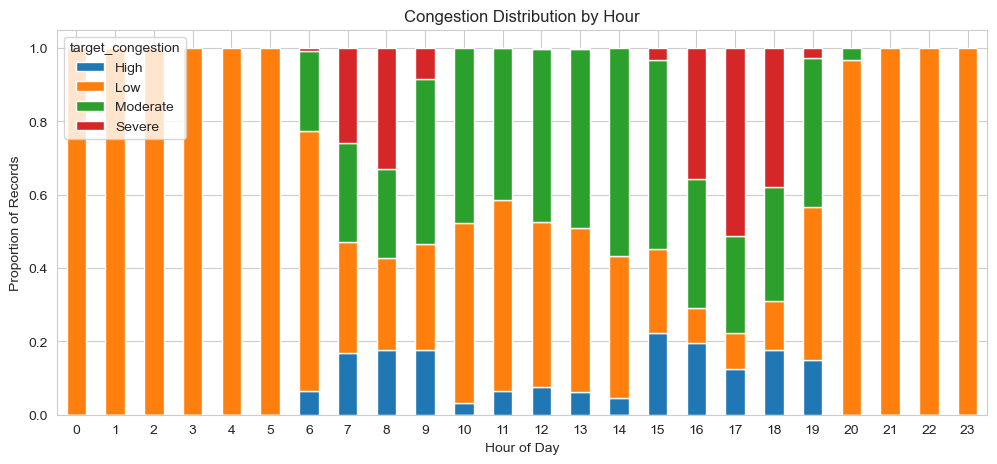

In [18]:
# Calculate the proportion of each congestion class by hour
congestion_by_hour = pd.crosstab(
    df["hour"],
    df["target_congestion"],
    normalize="index"
)

# Plot congestion proportions for each hour
congestion_by_hour.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Congestion Distribution by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Proportion of Records")
plt.xticks(rotation=0)
plt.show()

### Average traffic by intersection

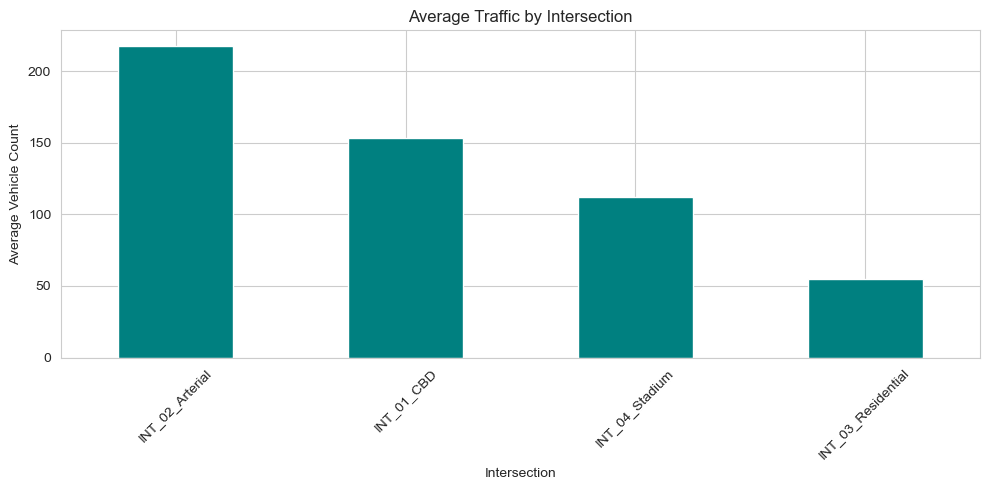

In [19]:
# Calculate average vehicle count at each intersection
traffic_by_intersection = df.groupby(
    "intersection_id"
)["vehicle_count"].mean().sort_values(ascending=False)

# Plot traffic volume by intersection
traffic_by_intersection.plot(kind="bar", color="teal")

plt.title("Average Traffic by Intersection")
plt.xlabel("Intersection")
plt.ylabel("Average Vehicle Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Queue length vs vehicle count

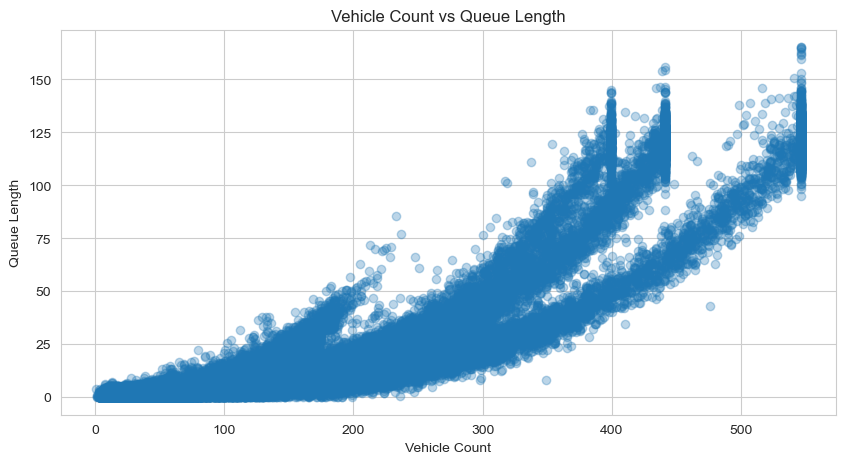

In [20]:
# Compare vehicle count with queue length
plt.scatter(
    df["vehicle_count"],
    df["queue_length_veh"],
    alpha=0.3
)

plt.title("Vehicle Count vs Queue Length")
plt.xlabel("Vehicle Count")
plt.ylabel("Queue Length")
plt.show()

### Traffic rolling average

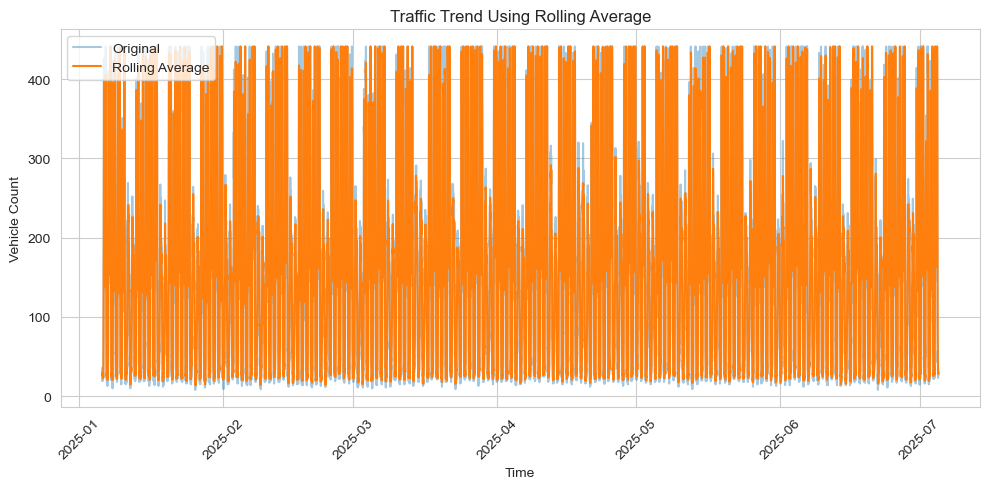

In [21]:
# Select one intersection and sort its records by time
traffic = df[df["intersection_id"] == df["intersection_id"].iloc[0]]
traffic = traffic.sort_values("timestamp").copy()

# Calculate a moving average over four observations
traffic["rolling_average"] = traffic["vehicle_count"].rolling(4).mean()

# Plot original traffic and smoothed traffic
plt.plot(traffic["timestamp"], traffic["vehicle_count"], alpha=0.4, label="Original")
plt.plot(traffic["timestamp"], traffic["rolling_average"], label="Rolling Average")

plt.title("Traffic Trend Using Rolling Average")
plt.xlabel("Time")
plt.ylabel("Vehicle Count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Autocorrelation

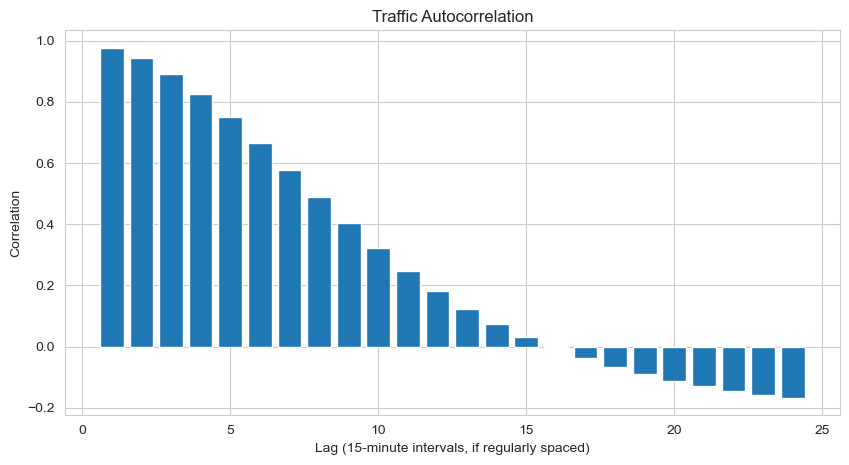

In [22]:
# Select one intersection and sort records by time
traffic = df[df["intersection_id"] == df["intersection_id"].iloc[0]]
traffic = traffic.sort_values("timestamp")

# Calculate correlation with previous observations
values = traffic["vehicle_count"].dropna()
lags = range(1, 25)
correlations = [values.autocorr(lag=lag) for lag in lags]

# Plot autocorrelation values
plt.bar(lags, correlations)

plt.title("Traffic Autocorrelation")
plt.xlabel("Lag (15-minute intervals, if regularly spaced)")
plt.ylabel("Correlation")
plt.show()

### Holiday vs non-holiday traffic

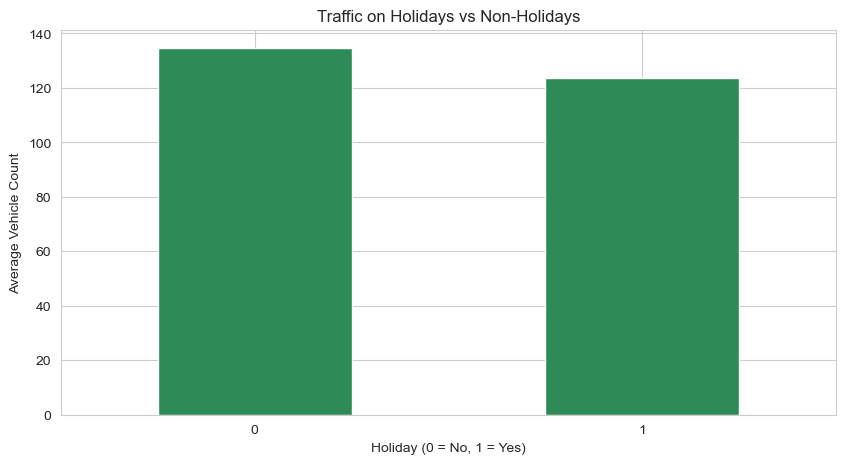

In [23]:
# Calculate average traffic on holidays and non-holidays
holiday_traffic = df.groupby("is_holiday")["vehicle_count"].mean()

# Plot the comparison
holiday_traffic.plot(kind="bar", color="seagreen")

plt.title("Traffic on Holidays vs Non-Holidays")
plt.xlabel("Holiday (0 = No, 1 = Yes)")
plt.ylabel("Average Vehicle Count")
plt.xticks(rotation=0)
plt.show()

## Conclusion

Exploratory data analysis was performed on the cleaned urban traffic dataset.

- **Traffic patterns:** Hourly, daily, and weekly visualizations help identify changes in traffic volume over time.
- **Traffic speed:** Speed distributions and speed-versus-volume plots help explore the relationship between traffic load and vehicle speed.
- **Congestion:** Congestion class balance and hourly comparisons help identify when congestion occurs.
- **Environmental and incident factors:** Rainfall, incidents, and holidays were compared with traffic measurements to explore possible associations.
- **Location analysis:** Intersection and queue-length visualizations help compare traffic conditions across locations.
- **Feature relationships:** Correlation and autocorrelation plots help explore relationships between variables and past traffic observations.

These findings provide a starting point for selecting features and developing traffic prediction models. Relationships observed in these charts do not, by themselves, establish causation.